# Credit Card Fraud Detection: finding 473 needles in 283,000 transactions

**The question:** two days of European card transactions (September 2013) contain 284,807 payments, and only **492 of them are fraud (0.17%)**. What separates fraud from normal payments, how do you even *measure* a detector when 99.8% of cases are normal, and what is a sensible way to decide when to raise the alarm?

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data (including a metric trap in the legacy notebook)
4. Hypotheses and why we chose each test
5. H1: do fraudulent payments have different amounts?
6. H2: does fraud depend on the time of day?
7. H3: which measurements separate fraud?
8. H4 and H5: a leak-free model ladder, and two default traps
9. H6: when should the alarm ring? (a cost-based decision)
10. H7: does a time-ordered test change the story?
11. Takeaways
12. Limitations

**Run it:** `uv run jupyter lab ML/credit-card-fraud-detection/credit_card_fraud_detection.ipynb`, or *Run All* in any Jupyter. The 150 MB data file downloads itself on the first run (about 15 seconds) and the notebook takes about 6 minutes in total.

## 1. 💡 The simple analogy

Imagine a **stadium with 600 people, and exactly one of them is a ticket forger**. A guard who says *"everyone here is honest"* is right about 599 out of 600 people, which is **99.8% accurate**. And completely useless: he has caught nobody.

That is the trap of **rare-event detection**: *accuracy* looks wonderful even for a detector that does nothing, so we need scorecards that look only at the rare cases:

- **Recall (sensitivity):** of the real forgers, what share did the guard catch?
- **Precision:** of the people the guard pulled aside, what share were really forgers?
- **Average precision (AUPRC):** one number that summarises the trade-off between those two across *all* possible alarm settings. It is the right headline metric when the thing you are hunting is rare, because (unlike accuracy or ROC-AUC) it is not flattered by the sea of easy normal cases.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the random seed keeps the notebook reproducible and avoids "magic numbers". With the seed fixed, every cross-validation split and every model comes out the same each time you run it.

In [1]:
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
DATA_PATH = Path("data/creditcard.csv")
OUT_DIR = Path("outputs")
SEED = 42
CV_SPLITS, CV_REPEATS = 5, 2
REVIEW_COST = 5.0  # assumed cost in dollars of an analyst reviewing one flagged payment
TEAL, ORANGE, NAVY, GREY = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. Audit the data first

*What:* load the file and check what each column means. *Why:* before testing anything we need to know how many cases we have, how rare fraud is, whether anything is duplicated, and what the columns are.

**The columns.** For privacy, the bank published most features only after a mathematical disguise called **PCA** (principal component analysis), so `V1` to `V28` are **anonymised numbers with no readable meaning**. The two readable columns are `Time` (seconds since the first transaction in the file) and `Amount` (euros). `Class` is 1 for fraud and 0 for normal. The data is from the ULB Machine Learning Group, released under the Open Database Licence.

> **A metric trap in the legacy notebook.** It reported *"Accuracy 99.92%"* as its headline and computed two scores it called "Specificity" and "Sensitivity". But its "specificity" formula was actually **precision** and its "sensitivity" formula was actually the **negative predictive value** (the share of "normal" calls that were right), so the standard definitions were swapped or mislabelled. We use the standard definitions throughout and put the accuracy of the do-nothing detector next to every result.

In [2]:
def load_transactions(path: Path = DATA_PATH) -> pd.DataFrame:
    """Loads the credit card transactions, downloading them on first use.

    Args:
        path: Where to cache the raw CSV (about 150 MB).

    Returns:
        DataFrame with Time, V1-V28, Amount and Class (284,807 rows).

    Raises:
        ValueError: If the file does not have the expected shape or contains nulls.
    """
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(DATA_URL, path)
    table = pd.read_csv(path)
    if table.shape != (284_807, 31) or table.isna().any().any():
        raise ValueError(f"Unexpected data: shape={table.shape}")
    return table


raw = load_transactions()
duplicated = raw.duplicated()
print(f"Transactions: {len(raw):,}   Missing values: {int(raw.isna().sum().sum())}")
print(f"Fraud: {int(raw['Class'].sum())} ({raw['Class'].mean():.3%})")
print(
    f"Exact duplicate rows: {duplicated.sum():,} "
    f"(of which {int((duplicated & (raw['Class'] == 1)).sum())} are fraud)"
)

data = raw.drop_duplicates().reset_index(drop=True)
FEATURES = [c for c in data.columns if c not in ("Time", "Class")]
X, y = data[FEATURES], data["Class"]
do_nothing_accuracy = 1 - y.mean()
print(
    f"\nAfter removing duplicates: {len(data):,} transactions, {int(y.sum())} frauds "
    f"({y.mean():.3%})"
)
print(
    f"Accuracy of a detector that never flags anything: {do_nothing_accuracy:.3%} "
    f"(catches 0 of {int(y.sum())} frauds)"
)
raw[["Time", "Amount"]].describe().round(1).T

Transactions: 284,807   Missing values: 0
Fraud: 492 (0.173%)
Exact duplicate rows: 1,081 (of which 19 are fraud)



After removing duplicates: 283,726 transactions, 473 frauds (0.167%)
Accuracy of a detector that never flags anything: 99.833% (catches 0 of 473 frauds)


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.9,47488.1,0.0,54201.5,84692.0,139320.5,172792.0
Amount,284807.0,88.3,250.1,0.0,5.6,22.0,77.2,25691.2


**How to read this.** The file has **no missing values**, but it has **1,081 exact duplicate rows**, including 19 duplicated frauds. Duplicates are dangerous in cross-validation: if one copy lands in the training fold and its twin in the test fold, the model is "tested" on something it has memorised. We **remove them**, leaving **283,726 transactions with 473 frauds (0.167%)**.

The punchline: **a detector that flags nothing is 99.83% accurate**. So when you see a fraud model advertise "99.9% accuracy", the information is in the missing 0.07 percentage points, and accuracy is not the right scoreboard.

We also **leave `Time` out of the model**: it only covers two days, so a model could learn "fraud happens at second 93,000 of the log", which will not generalise. (We will still *study* the time of day below.)

## 4. 🔬 Hypotheses and why we chose each test

Here are the questions, each with its null (H₀, "nothing special") and alternative (Hₐ), written **before** looking at any p-values:

| # | Question | H₀ | Hₐ | Method |
|---|---|---|---|---|
| H1 | Do fraudulent payments have different amounts? | Same distribution | Different | Mann-Whitney U with Cliff's δ |
| H2 | Does the chance of fraud depend on the time of day? | Fraud rate is the same in every hour | It varies | Chi-square test of homogeneity, Cramér's V, Wilson CIs |
| H3 | Which anonymised features separate fraud from normal? | Same distribution | Different | Mann-Whitney U, single-feature AUC with a Hanley-McNeil CI, Holm correction over 29 tests |
| H4 | Do complex models beat logistic regression at finding fraud? | AP difference = 0 | A complex model is better | Leak-free repeated stratified CV with paired Nadeau-Bengio tests |
| H5 | Do "common-sense defaults" (class weights, automatic early stopping) help? | No change | A change | Same CV, compared directly |
| H6 | What alarm threshold minimises the total cost of fraud? | (decision analysis) | n/a | Cost curve on out-of-fold probabilities |
| H7 | Does a time-ordered test give a different answer from a random split? | Same score | Different | Train on the first 70% of time, test on the rest |

**Why Mann-Whitney U and Cliff's δ?** Mann-Whitney U lines every transaction up from lowest to highest value and asks whether fraud tends to sit higher in the line. It doesn't assume a bell shape and isn't hijacked by a few huge payments. **Cliff's δ** is *P(a fraud has the higher value) − P(it has the lower value)*, from −1 to +1 (|δ| about 0.15 small, 0.33 medium, 0.47 large). It has a bonus meaning: **(δ + 1) / 2 is the AUC of that single feature**, the chance that it ranks a random fraud above a random normal payment.

**Why Holm correction?** We run 29 feature tests; do enough tests and some will look "significant" by luck, like buying more lottery tickets. Holm adjusts the p-values so the chance of *any* false alarm across all 29 stays at 5%.

## 5. H1: do fraudulent payments have different amounts?

*What:* compare the `Amount` of fraudulent and normal payments. *Why a log scale?* Amounts range from 0 to 25,000 euros with a long tail, so we plot them on a log scale where "10x more" is the same step everywhere.

Median amount: fraud 9.82, normal 22.00
Mean amount:   fraud 123.87, normal 88.41
Mann-Whitney p = 2.7e-05, Cliff's delta = -0.11
Share of payments under 1 euro: fraud 14.0%, normal 5.9%


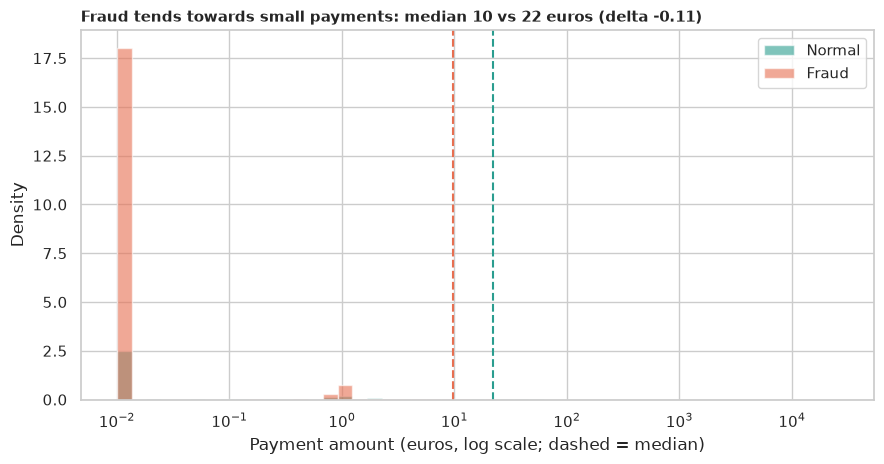

In [3]:
amount_fraud = data.loc[y == 1, "Amount"]
amount_normal = data.loc[y == 0, "Amount"]
mwu_amount = stats.mannwhitneyu(amount_fraud, amount_normal)
delta_amount = 2 * mwu_amount.statistic / (len(amount_fraud) * len(amount_normal)) - 1

print(f"Median amount: fraud {amount_fraud.median():.2f}, normal {amount_normal.median():.2f}")
print(f"Mean amount:   fraud {amount_fraud.mean():.2f}, normal {amount_normal.mean():.2f}")
print(f"Mann-Whitney p = {fmt_p(mwu_amount.pvalue)}, Cliff's delta = {delta_amount:+.2f}")
print(
    f"Share of payments under 1 euro: fraud {(amount_fraud < 1).mean():.1%}, "
    f"normal {(amount_normal < 1).mean():.1%}"
)

fig, ax = plt.subplots(figsize=(9, 4.8))
bins = np.logspace(-2, np.log10(data["Amount"].max()), 50)
for values, color, label in ((amount_normal, TEAL, "Normal"), (amount_fraud, ORANGE, "Fraud")):
    ax.hist(values.clip(lower=0.01), bins=bins, density=True, alpha=0.6, color=color, label=label)
    ax.axvline(values.median(), color=color, ls="--")
ax.set_xscale("log")
ax.set_xlabel("Payment amount (euros, log scale; dashed = median)")
ax.set_ylabel("Density")
ax.legend()
ax.set_title(
    f"Fraud tends towards small payments: median {amount_fraud.median():.0f} vs "
    f"{amount_normal.median():.0f} euros (delta {delta_amount:+.2f})",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_amounts.png", dpi=150)
plt.show()

**How to read this.** The median fraudulent payment is about **9.82 euros against 22.00 for a normal payment**, and Cliff's δ is about **−0.11**: a *small* effect, but with so many payments Mann-Whitney is highly significant (p ≈ 3e-5), so **we reject H₀**. In plain terms: fraud skews towards *smaller* payments, plausibly because criminals test a stolen card with a tiny purchase before spending big. But the mean fraud amount (about 124 euros) is *higher* than the mean normal amount (about 88 euros), because a few fraudulent payments are large. **Amount alone is a weak detector** (AUC = (δ + 1)/2 ≈ 0.44 means it ranks fraud *below* normal slightly more often than above). One more detail supports the "card testing" idea: **14.0% of fraudulent payments are under 1 euro, against 5.9% of normal ones**.

## 6. H2: does fraud depend on the time of day?

*What:* the `Time` column counts seconds since the first transaction, so we turn it into an **hour since the start of the log** (0 to 23, with the two days folded together). *Caveat:* the file doesn't give the real clock time, but the volume pattern below (a quiet trough in hours 1 to 5) suggests the log starts around midnight, so we can read the hours roughly as clock hours.

*Test:* a **chi-square test of homogeneity** on the table of hour × (fraud, normal). **H₀:** the fraud rate is the same in every hour. **Cramér's V** (0 = no association, 1 = perfect) is the effect size, and each hour's fraud rate gets a **Wilson 95% confidence interval** (a well-behaved CI for small proportions).

Chi-square: chi2(23) = 548, p = 3.1e-101, Cramer's V = 0.044
Smallest expected count in a cell: 3.7
Overall fraud rate 0.167%; peak hour 2: 1.45% (8.7x the overall rate)


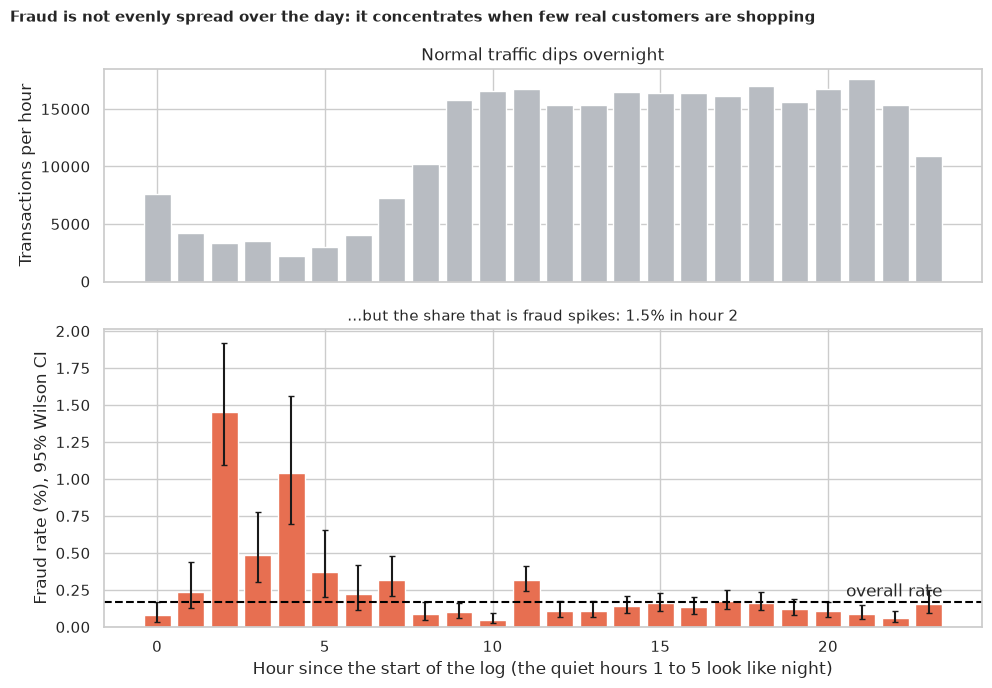

In [4]:
hour = (data["Time"] // 3600).astype(int) % 24
by_hour = pd.DataFrame(
    {"transactions": hour.value_counts().sort_index(), "frauds": y.groupby(hour).sum()}
)
by_hour["rate"] = by_hour["frauds"] / by_hour["transactions"]
by_hour["ci_low"], by_hour["ci_high"] = proportion_confint(
    by_hour["frauds"], by_hour["transactions"], method="wilson"
)

table = pd.crosstab(hour, y)
chi2, p_hour, dof, expected = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / table.to_numpy().sum())
peak = by_hour["rate"].idxmax()
print(f"Chi-square: chi2({dof}) = {chi2:.0f}, p = {fmt_p(p_hour)}, Cramer's V = {cramers_v:.3f}")
print(f"Smallest expected count in a cell: {expected.min():.1f}")
print(
    f"Overall fraud rate {y.mean():.3%}; peak hour {peak}: {by_hour.loc[peak, 'rate']:.2%} "
    f"({by_hour.loc[peak, 'rate'] / y.mean():.1f}x the overall rate)"
)

fig, axes = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]}
)
axes[0].bar(by_hour.index, by_hour["transactions"], color=GREY)
axes[0].set_ylabel("Transactions per hour")
axes[0].set_title("Normal traffic dips overnight")
err = [by_hour["rate"] - by_hour["ci_low"], by_hour["ci_high"] - by_hour["rate"]]
axes[1].bar(by_hour.index, by_hour["rate"] * 100, yerr=np.array(err) * 100, color=ORANGE, capsize=2)
axes[1].axhline(y.mean() * 100, color="black", ls="--")
axes[1].text(23.4, y.mean() * 100 + 0.04, "overall rate", ha="right")
axes[1].set_xlabel("Hour since the start of the log (the quiet hours 1 to 5 look like night)")
axes[1].set_ylabel("Fraud rate (%), 95% Wilson CI")
axes[1].set_title(
    f"...but the share that is fraud spikes: {by_hour.loc[peak, 'rate']:.1%} in hour {peak}",
    fontsize=11,
)
fig.suptitle(
    "Fraud is not evenly spread over the day: it concentrates when few real customers are shopping",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_fraud_by_hour.png", dpi=150)
plt.show()

**How to read this.** The chi-square test gives χ²(23) ≈ 548 and p ≈ 3e-101, so **we reject H₀: fraud is not evenly spread across the day**. The effect is clear in the chart: the volume of normal traffic (top) collapses overnight, but fraud does not, so the fraud *rate* (bottom) peaks at **hour 2 with about 1.45%, roughly 9 times the overall rate**, while midday hours sit below the overall average. Cramér's V ≈ 0.04 is small *in absolute terms* (the overwhelming majority of transactions are normal at every hour), but because fraud is so rare, an 8-9x change in its rate is exactly the sort of signal a detector can use. One caveat: the smallest expected count in a cell is 3.7 (a night hour's fraud cell), just under the usual rule of thumb of 5, but only a few of the 48 cells are that small and the statistic is enormous, so the conclusion is not in doubt.

> We keep `Time` out of the model because two days can't tell us whether the "night" pattern is stable. A real system with months of data could use the hour of day.

## 7. H3: which measurements separate fraud?

*What:* for each of the 29 features (`V1` to `V28` and `Amount`), a Mann-Whitney test with Cliff's δ, and a 95% CI from the **Hanley-McNeil formula** for the AUC (a standard analytic standard error for AUC; the bootstrap would take too long on 283,000 rows). Remember **(δ + 1) / 2 = the single-feature AUC**.

In [5]:
def auc_ci(auc: float, n_pos: int, n_neg: int) -> tuple[float, float]:
    """95% CI for an AUC using the Hanley-McNeil (1982) standard error.

    Args:
        auc: Observed AUC.
        n_pos: Number of positive cases (fraud).
        n_neg: Number of negative cases (normal).

    Returns:
        CI lower bound, CI upper bound.
    """
    q1, q2 = auc / (2 - auc), 2 * auc**2 / (1 + auc)
    variance = (auc * (1 - auc) + (n_pos - 1) * (q1 - auc**2) + (n_neg - 1) * (q2 - auc**2)) / (
        n_pos * n_neg
    )
    half = 1.96 * np.sqrt(variance)
    return auc - half, auc + half


n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
rows = {}
for feature in FEATURES:
    test = stats.mannwhitneyu(X.loc[y == 1, feature], X.loc[y == 0, feature])
    auc = test.statistic / (n_pos * n_neg)
    lo, hi = auc_ci(auc, n_pos, n_neg)
    rows[feature] = {
        "delta": 2 * auc - 1,
        "auc": auc,
        "auc_low": lo,
        "auc_high": hi,
        "p": test.pvalue,
    }
features_table = pd.DataFrame(rows).T
features_table["p_holm"] = multipletests(features_table["p"], method="holm")[1]
features_table["separation"] = np.maximum(features_table["auc"], 1 - features_table["auc"])
features_table["strength"] = (features_table["auc"] - 0.5).abs()
features_table = features_table.sort_values("strength", ascending=False)
print(
    f"Significant after Holm correction: {(features_table['p_holm'] < 0.05).sum()} of "
    f"{len(features_table)}"
)
features_table.head(8)[
    ["delta", "separation", "auc", "auc_low", "auc_high", "p_holm"]
].style.format(
    {
        "delta": "{:+.2f}",
        "separation": "{:.3f}",
        "auc": "{:.3f}",
        "auc_low": "{:.3f}",
        "auc_high": "{:.3f}",
        "p_holm": fmt_p,
    }
)

Significant after Holm correction: 25 of 29


,delta,separation,auc,auc_low,auc_high,p_holm
V14,-0.89,0.947,0.053,0.048,0.057,6.7e-247
V4,+0.87,0.936,0.936,0.921,0.952,4.5e-235
V12,-0.87,0.934,0.066,0.060,0.071,3.7e-233
V11,+0.83,0.915,0.915,0.897,0.932,1.2e-212
V10,-0.82,0.911,0.089,0.082,0.097,2.4e-208
V3,-0.82,0.909,0.091,0.084,0.099,2.1e-206
V2,+0.70,0.850,0.850,0.828,0.872,1.9e-151
V16,-0.68,0.841,0.159,0.146,0.171,2.4e-144


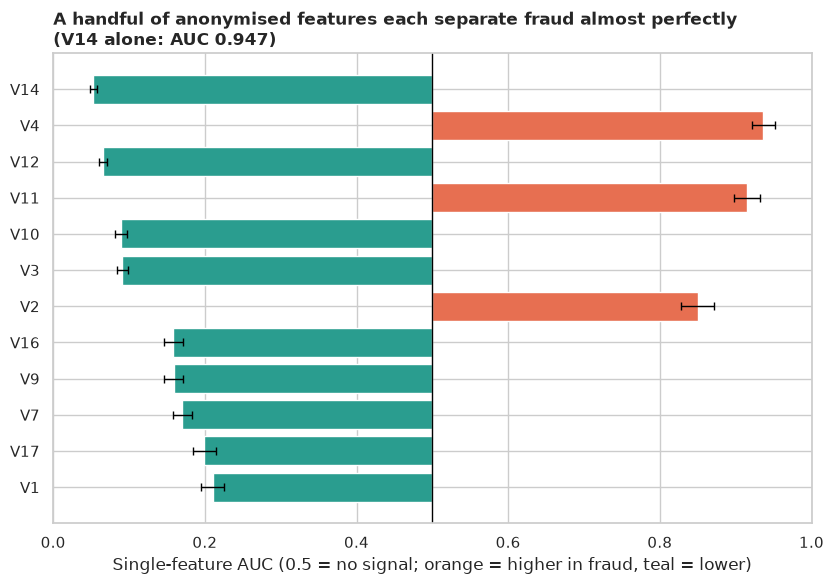

In [6]:
top = features_table.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6))
ypos = np.arange(len(top))
colors = np.where(top["auc"] > 0.5, ORANGE, TEAL)
ax.barh(ypos, top["auc"] - 0.5, left=0.5, color=colors)
ax.errorbar(
    top["auc"],
    ypos,
    xerr=[top["auc"] - top["auc_low"], top["auc_high"] - top["auc"]],
    fmt="none",
    ecolor="black",
    capsize=3,
    lw=1,
)
ax.axvline(0.5, color="black", lw=1)
ax.set_yticks(ypos, top.index)
ax.set_xlim(0, 1)
ax.set_xlabel("Single-feature AUC (0.5 = no signal; orange = higher in fraud, teal = lower)")
best_feature = features_table.index[0]
ax.set_title(
    f"A handful of anonymised features each separate fraud almost perfectly\n"
    f"({best_feature} alone: AUC {features_table['separation'].iloc[0]:.3f})",
    loc="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_feature_separation.png", dpi=150)
plt.show()

**How to read this.** (Teal bars point left of 0.5: lower in fraud. Orange bars point right: higher in fraud.)

- **The anonymised features carry a lot of signal.** The strongest, `V14`, has a single-feature AUC of about **0.947** (δ ≈ −0.89; the `separation` column ignores direction, while `auc` is the chance that the feature is *higher* in a fraud, so `V14`'s 0.053 means it is *lower* in fraud about 95% of the time). `V4`, `V12`, `V11`, `V10` and `V3` are almost as strong (separation 0.91 to 0.94), so **every one of the top six features is by itself a good detector**.
- The CIs are narrow (about ±0.005 for `V14`), though the fraud group is only 473 cases, which is where most of the remaining uncertainty lives.
- **25 of the 29 features are significant after Holm correction**, so as in many large data sets the p-values are uninformative and the **effect size** is what ranks the features. `Amount` is a weak feature (AUC about 0.44), in line with H1.

Several features measure overlapping things (PCA outputs are uncorrelated by construction on the original data, but the sample can still tangle them), so we'll let a model combine them rather than hand-pick.

## 8. H4 and H5: a leak-free model ladder, and two default traps

*What:* now the practical question: **how well can a model find fraud it hasn't seen, and which ingredients help?** The ladder:

1. **Do nothing:** never flag anything. The bar to beat.
2. **Logistic regression**, a transparent linear model. Then the same with **balanced class weights**, the standard "common-sense" fix for rarity.
3. **A pruned decision tree** (depth 8). The legacy notebook used an unpruned tree, which memorises its training data and took minutes to fit.
4. **Gradient boosting** (`HistGradientBoostingClassifier`) twice, once with scikit-learn's **default early stopping** and once without it.
5. **Random forest.**

**How we avoid cheating (data leakage).** Scaling lives **inside** each `Pipeline`, so it is learned from training folds only. We use **stratified** folds (every fold has the same 0.17% fraud rate; a plain random split could hand a fold only a handful of frauds) and **repeat** 5-fold CV twice (10 train/test splits). Duplicates were removed up front.

**How we score.** **Average precision (AP)** is our headline: a summary of the precision-recall trade-off (a detector that does nothing scores about 0.0017, the fraud rate; perfection is 1). We also report **ROC-AUC**, and **recall** and **precision** at the default decision threshold of 0.5. Confidence intervals use the **Nadeau-Bengio correction**: the 10 scores aren't independent because the splits reuse mostly the same transactions, much like judges who all read the same pages of a report, so a plain interval would be too narrow.

In [7]:
def build_models() -> dict[str, object]:
    """Builds the model ladder. Scaling lives inside each pipeline (no leakage).

    Returns:
        Model name mapped to an unfitted estimator.
    """
    boosting = {
        "max_depth": 5,
        "learning_rate": 0.1,
        "max_iter": 150,
        "min_samples_leaf": 40,
        "l2_regularization": 1.0,
        "random_state": SEED,
    }
    return {
        "Do nothing": DummyClassifier(strategy="prior"),
        "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "Logistic regression, balanced weights": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")
        ),
        "Decision tree (depth 8)": DecisionTreeClassifier(
            max_depth=8, min_samples_leaf=5, random_state=SEED
        ),
        "Boosting, default early stopping": HistGradientBoostingClassifier(
            max_depth=5, learning_rate=0.1, max_iter=150, random_state=SEED
        ),
        "Boosting, no early stopping": HistGradientBoostingClassifier(
            early_stopping=False, **boosting
        ),
        "Random forest": RandomForestClassifier(
            100, min_samples_leaf=3, max_samples=0.5, n_jobs=-1, random_state=SEED
        ),
    }


def corrected_ci(scores: np.ndarray, n_train: int, n_test: int) -> tuple[float, float, float]:
    """95% CI for a mean CV score using the Nadeau-Bengio variance correction.

    Args:
        scores: Per-split scores.
        n_train: Training rows per split.
        n_test: Test rows per split.

    Returns:
        Mean, CI lower bound, CI upper bound (upper bound capped at 1).
    """
    k = len(scores)
    se = np.sqrt((1 / k + n_test / n_train) * np.var(scores, ddof=1))
    half = stats.t.ppf(0.975, k - 1) * se
    return float(scores.mean()), float(scores.mean() - half), float(min(1.0, scores.mean() + half))


def corrected_paired_p(diff: np.ndarray, n_train: int, n_test: int) -> float:
    """Two-sided p-value for "do two models differ?" on identical splits.

    Args:
        diff: Per-split score differences between two models.
        n_train: Training rows per split.
        n_test: Test rows per split.

    Returns:
        p-value from the corrected resampled t-test.
    """
    k = len(diff)
    se = np.sqrt((1 / k + n_test / n_train) * np.var(diff, ddof=1))
    return float(2 * stats.t.sf(abs(diff.mean() / se), k - 1))

Now run the cross-validation. Every model sees **exactly the same 10 splits**, which is what allows the *paired* comparison afterwards. (This cell takes about 5 minutes: the forest and the tree are the slow ones.)

In [8]:
cv = RepeatedStratifiedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=SEED)
n_test = len(X) // CV_SPLITS
n_train = len(X) - n_test
scoring = {
    "ap": "average_precision",
    "auc": "roc_auc",
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
}

fold_scores, rows = {}, {}
for name, model in build_models().items():
    res = cross_validate(model, X, y, cv=cv, scoring=scoring)
    fold_scores[name] = {m: res[f"test_{m}"] for m in scoring}
    ap_mean, ap_lo, ap_hi = corrected_ci(res["test_ap"], n_train, n_test)
    auc_mean, auc_lo, auc_hi = corrected_ci(res["test_auc"], n_train, n_test)
    rows[name] = {
        "AP": ap_mean,
        "AP low": ap_lo,
        "AP high": ap_hi,
        "ROC-AUC": auc_mean,
        "AUC low": auc_lo,
        "AUC high": auc_hi,
        "recall @0.5": res["test_recall"].mean(),
        "precision @0.5": res["test_precision"].mean(),
    }
results = pd.DataFrame(rows).T
results[["AP", "ROC-AUC", "recall @0.5", "precision @0.5"]].round(3)

,AP,ROC-AUC,recall @0.5,precision @0.5
Do nothing,0.002,0.500,0.000,0.000
Logistic regression,0.742,0.976,0.603,0.863
"Logistic regression, balanced weights",0.730,0.977,0.909,0.059
Decision tree (depth 8),0.750,0.905,0.739,0.892
"Boosting, default early stopping",0.644,0.831,0.695,0.616
"Boosting, no early stopping",0.830,0.979,0.783,0.938
Random forest,0.829,0.951,0.759,0.923


**How to read this.** (AP: higher is better; the do-nothing row shows the floor.)

- **Do nothing:** AP ≈ 0.002 (the fraud rate), recall 0. It is 99.83% *accurate*, yet worthless.
- **Logistic regression:** AP ≈ **0.74**, ROC-AUC ≈ 0.976. At the default threshold it catches **about 60%** of frauds and about **86%** of its alarms are real.
- **Balanced class weights do not help AP** (0.73): they simply move the operating point. Recall jumps to about **91%** but **precision collapses to about 6%**: about 16 false alarms for every real fraud. Same ranking skill, very different behaviour at 0.5.
- **The best models are the boosted trees and the forest: AP ≈ 0.83**, with recall around 76% to 78% and precision above 92% at the default threshold. The pruned decision tree is clearly behind (AP ≈ 0.75).
- **Trap 2 (the default early stopping): gradient boosting with scikit-learn's automatic early stopping scores AP ≈ 0.64 and ROC-AUC only about 0.83**, against AP ≈ 0.83 and AUC ≈ 0.98 for the *same model with early stopping switched off*. Why? Automatic early stopping holds back a validation slice and halts training when its loss stops improving. With only about 0.17% fraud, that slice contains a few dozen frauds, the loss is noisy, and training stops far too soon in some folds. A "sensible default" silently ruined the model.

Are those gaps real, or just noise between the 10 splits? The paired test settles it.

In [9]:
reference = "Boosting, no early stopping"
comparison = {}
for name, scores in fold_scores.items():
    if name in (reference, "Do nothing"):
        continue
    diff = scores["ap"] - fold_scores[reference]["ap"]
    comparison[name] = {
        "AP minus reference": diff.mean(),
        "paired p": corrected_paired_p(diff, n_train, n_test),
    }
diff_weights = (
    fold_scores["Logistic regression, balanced weights"]["ap"]
    - fold_scores["Logistic regression"]["ap"]
)
print(
    "Balanced weights vs plain logistic regression: AP difference "
    f"{diff_weights.mean():+.3f}, paired p = "
    f"{corrected_paired_p(diff_weights, n_train, n_test):.3f}"
)
pd.DataFrame(comparison).T.style.format({"AP minus reference": "{:+.3f}", "paired p": "{:.4f}"})

Balanced weights vs plain logistic regression: AP difference -0.012, paired p = 0.226


,AP minus reference,paired p
Logistic regression,-0.088,0.0001
"Logistic regression, balanced weights",-0.100,0.0003
Decision tree (depth 8),-0.081,0.0039
"Boosting, default early stopping",-0.186,0.0011
Random forest,-0.002,0.8619


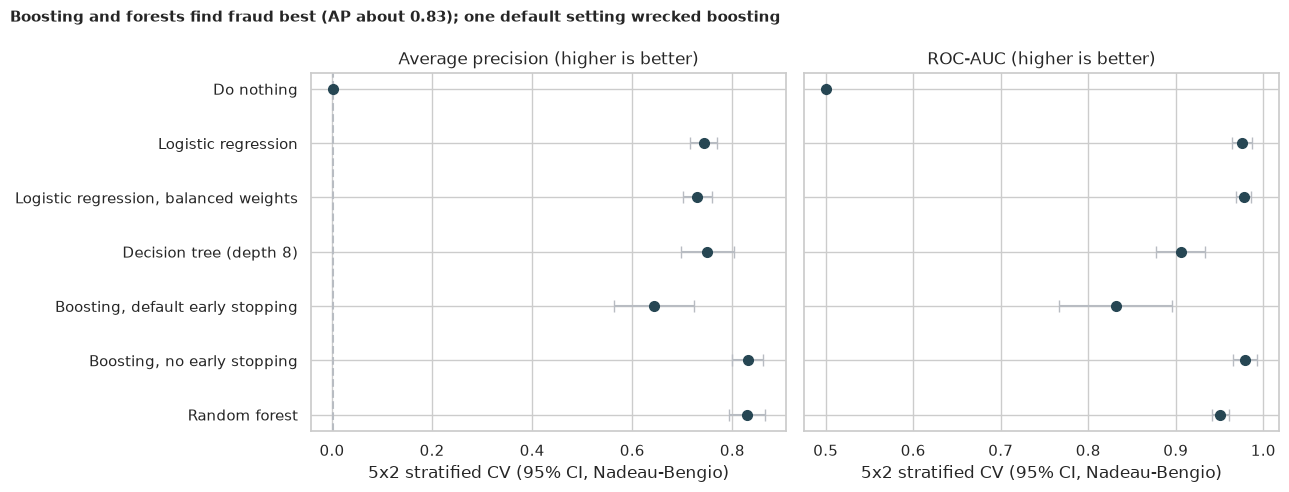

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
names = list(results.index)
ypos = np.arange(len(names))
for ax, metric, low, high, title in (
    (axes[0], "AP", "AP low", "AP high", "Average precision (higher is better)"),
    (axes[1], "ROC-AUC", "AUC low", "AUC high", "ROC-AUC (higher is better)"),
):
    ax.errorbar(
        results[metric],
        ypos,
        xerr=[results[metric] - results[low], results[high] - results[metric]],
        fmt="o",
        color=NAVY,
        ecolor=GREY,
        capsize=4,
        markersize=7,
    )
    ax.set_title(title)
    ax.set_xlabel(f"{CV_SPLITS}x{CV_REPEATS} stratified CV (95% CI, Nadeau-Bengio)")
axes[0].set_yticks(ypos, names)
axes[0].invert_yaxis()
axes[0].axvline(y.mean(), color=GREY, ls="--")
fig.suptitle(
    "Boosting and forests find fraud best (AP about 0.83); one default setting wrecked boosting",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_model_comparison.png", dpi=150)
plt.show()

**How to read this (paired test table and chart).**

- **Boosting without early stopping is the reference.** Versus it, **logistic regression is clearly worse** (about −0.09 AP, p well below 0.05), the **decision tree is worse** (about −0.08) and **boosting with default early stopping is dramatically worse** (about −0.19).
- **The random forest is not distinguishable from the reference** (AP difference near 0, large p): two different tree ensembles reach the same ceiling, around AP 0.83. **We fail to reject H₀ between them.**
- **Balanced class weights on logistic regression** barely change AP versus plain logistic regression (the extra printed line above gives the paired difference and p-value): re-weighting classes changes *where the threshold sits*, not how well the model *ranks* fraud above normal.
- The chart's ROC-AUC panel flatters everything (all the real models sit at 0.95 to 0.98) while the AP panel separates them: another sign of why AP is the better scoreboard for rare events.

## 9. H6: when should the alarm ring? (a cost-based decision)

*What:* a detector outputs a **probability of fraud**; somebody must choose a **threshold** above which the payment is blocked or reviewed. The default of 0.5 is arbitrary. The honest way to choose is by **cost**: a missed fraud costs the money of that payment, and a false alarm costs an analyst's review time. We assume **a review costs 5 euros** (an assumption, clearly labelled; change `REVIEW_COST` at the top to test other values).

*How:* we use `cross_val_predict` to get an honest fraud probability for **every transaction** from a model that never saw it (5-fold stratified), using the best model (boosting). Then for every threshold from 0 to 1 we compute the total cost, and compare the cost-minimising threshold with the default 0.5 and with two naive strategies: **flag nothing** (lose every fraud) and **flag everything** (pay to review all 283,000 payments).

In [11]:
best_model = build_models()["Boosting, no early stopping"]
proba = cross_val_predict(
    best_model,
    X,
    y,
    cv=StratifiedKFold(CV_SPLITS, shuffle=True, random_state=SEED),
    method="predict_proba",
)[:, 1]
oof_ap = average_precision_score(y, proba)
oof_auc = roc_auc_score(y, proba)

amount = data["Amount"].to_numpy()
is_fraud = y.to_numpy() == 1


def total_cost(threshold: float) -> tuple[float, int, int]:
    """Total cost of flagging every payment with probability at or above ``threshold``.

    Args:
        threshold: Probability cut-off.

    Returns:
        Total cost (missed-fraud amounts plus review cost of false alarms), number of
        missed frauds and number of false alarms.
    """
    flagged = proba >= threshold
    missed = is_fraud & ~flagged
    false_alarms = ~is_fraud & flagged
    return (
        float(amount[missed].sum() + REVIEW_COST * false_alarms.sum()),
        int(missed.sum()),
        int(false_alarms.sum()),
    )


thresholds = np.linspace(0.001, 0.999, 500)
costs = np.array([total_cost(t)[0] for t in thresholds])
best_threshold = float(thresholds[costs.argmin()])
strategies = pd.DataFrame(
    {
        "Flag nothing": (amount[is_fraud].sum(), int(is_fraud.sum()), 0),
        "Default threshold 0.50": total_cost(0.5),
        f"Cost-optimal threshold {best_threshold:.2f}": total_cost(best_threshold),
        "Flag everything": (REVIEW_COST * (~is_fraud).sum(), 0, int((~is_fraud).sum())),
    },
    index=["total cost (euros)", "missed frauds", "false alarms"],
).T
print(f"Out-of-fold AP = {oof_ap:.3f}, ROC-AUC = {oof_auc:.3f}")
saving = 1 - strategies.iloc[2, 0] / strategies.iloc[0, 0]
print(
    f"The cost-optimal threshold saves {saving:.0%} of the cost of flagging nothing, and "
    f"{1 - strategies.iloc[2, 0] / strategies.iloc[1, 0]:.0%} versus the default 0.5"
)
strategies.style.format(
    {"total cost (euros)": "{:,.0f}", "missed frauds": "{:,.0f}", "false alarms": "{:,.0f}"}
)

Out-of-fold AP = 0.830, ROC-AUC = 0.981
The cost-optimal threshold saves 75% of the cost of flagging nothing, and 7% versus the default 0.5


,total cost (euros),missed frauds,false alarms
Flag nothing,"58,591",473,0
Default threshold 0.50,"15,921",103,22
Cost-optimal threshold 0.04,"14,795",82,93
Flag everything,"1,416,265",0,"283,253"


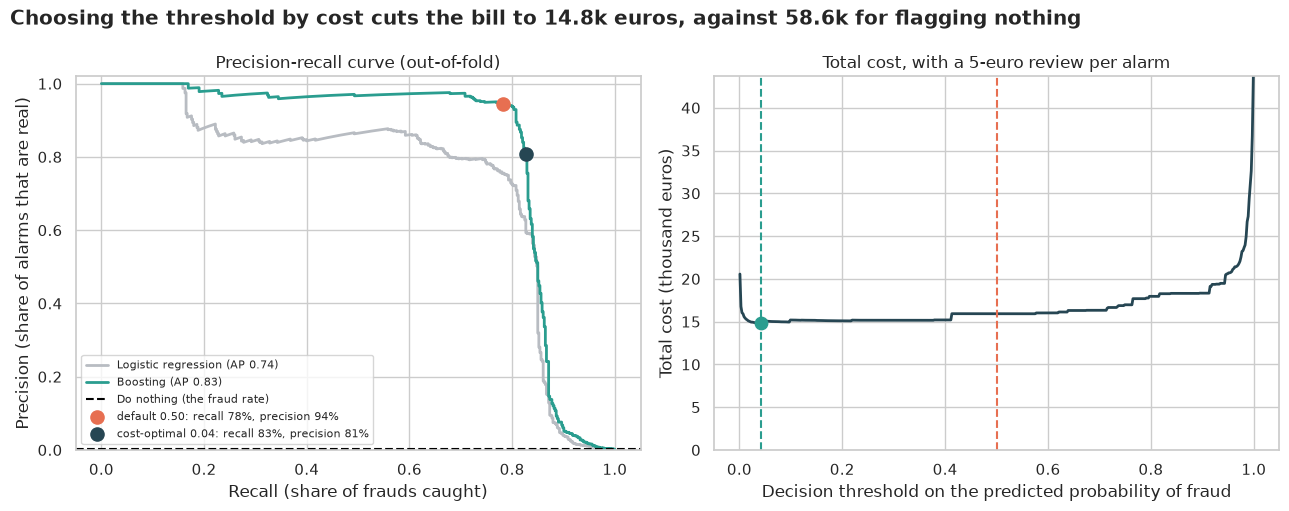

In [12]:
precision, recall, pr_thresholds = precision_recall_curve(y, proba)
lr_proba = cross_val_predict(
    build_models()["Logistic regression"],
    X,
    y,
    cv=StratifiedKFold(CV_SPLITS, shuffle=True, random_state=SEED),
    method="predict_proba",
)[:, 1]
lr_precision, lr_recall, _ = precision_recall_curve(y, lr_proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
axes[0].plot(
    lr_recall,
    lr_precision,
    color=GREY,
    lw=2,
    label=f"Logistic regression (AP {average_precision_score(y, lr_proba):.2f})",
)
axes[0].plot(recall, precision, color=TEAL, lw=2, label=f"Boosting (AP {oof_ap:.2f})")
axes[0].axhline(y.mean(), color="black", ls="--", label="Do nothing (the fraud rate)")
for threshold, label, color in (
    (0.5, "default 0.50", ORANGE),
    (best_threshold, f"cost-optimal {best_threshold:.2f}", NAVY),
):
    flagged = proba >= threshold
    r, p = (flagged & is_fraud).sum() / is_fraud.sum(), (flagged & is_fraud).sum() / flagged.sum()
    axes[0].scatter(
        r, p, s=90, color=color, zorder=3, label=f"{label}: recall {r:.0%}, precision {p:.0%}"
    )
axes[0].set_xlabel("Recall (share of frauds caught)")
axes[0].set_ylabel("Precision (share of alarms that are real)")
axes[0].set_ylim(0, 1.02)
axes[0].legend(fontsize=8, loc="lower left")
axes[0].set_title("Precision-recall curve (out-of-fold)")

axes[1].plot(thresholds, costs / 1000, color=NAVY, lw=2)
axes[1].axvline(0.5, color=ORANGE, ls="--")
axes[1].axvline(best_threshold, color=TEAL, ls="--")
axes[1].scatter([best_threshold], [costs.min() / 1000], color=TEAL, s=80, zorder=3)
axes[1].set_xlabel("Decision threshold on the predicted probability of fraud")
axes[1].set_ylabel("Total cost (thousand euros)")
axes[1].set_ylim(0, min(costs.max() / 1000, 60))
axes[1].set_title(f"Total cost, with a {REVIEW_COST:.0f}-euro review per alarm")
fig.suptitle(
    f"Choosing the threshold by cost cuts the bill to {strategies.iloc[2, 0] / 1000:.1f}k "
    f"euros, against {strategies.iloc[0, 0] / 1000:.1f}k for flagging nothing",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "05_cost_threshold.png", dpi=150)
plt.show()

**How to read this.**

- **Flagging nothing loses about 58,600 euros** (every fraud goes through) and **flagging everything costs about 1.4 million euros** (5 euros × 283,000 reviews). Neither is sensible.
- **The default threshold of 0.50** misses about **103** frauds and raises only **22** false alarms, for a total cost of about **15,900 euros**.
- **The cost-optimal threshold (about 0.04)** accepts more false alarms (about **93**) in exchange for catching more fraud (missing only about **82**), for a total cost of about **14,800 euros**: roughly **75% cheaper than no detector** and **7% cheaper than the default**.
- **Left chart:** the precision-recall curves. Boosting (teal) stays well above logistic regression (grey) across most of the range. The two dots mark the default threshold (fewer alarms, higher precision) and the cost-optimal one (more recall, lower precision). They are on the **same curve**; choosing a threshold just picks a point on it.
- **Right chart:** the cost curve is *flat near its minimum*: any threshold between roughly 0.02 and 0.5 costs within about 8% of the minimum (the curve only climbs steeply above about 0.9), so the exact choice isn't delicate, but the default of 0.5 is not the best. The honest answer depends on the **assumed review cost**: if a review cost 50 euros the best threshold would move up (fewer alarms), and if it cost 0.50 it would move down.

> *A fairness note:* the cost-optimal threshold was chosen using these same out-of-fold probabilities, which makes its saving slightly optimistic. A real deployment fixes the threshold on one period and confirms it on the next.

## 10. H7: does a time-ordered test change the story?

*What:* cross-validation shuffles transactions from both days together. In real life a model is trained on the **past** and used on the **future**, and fraud tactics drift. So we also test **in time order**: train on the first 70% of the log by time and test on the last 30%. For comparison we do a **random 70/30 split of the same size**. **H₀:** the two evaluations give the same score.

In [13]:
def holdout_scores(train_mask: np.ndarray, name: str) -> dict[str, float]:
    """Trains on ``train_mask`` rows and scores on the rest.

    Args:
        train_mask: Boolean array marking the training rows.
        name: Model name from :func:`build_models`.

    Returns:
        Average precision and ROC-AUC on the held-out rows.
    """
    model = build_models()[name].fit(X[train_mask], y[train_mask])
    scores = model.predict_proba(X[~train_mask])[:, 1]
    return {
        "AP": average_precision_score(y[~train_mask], scores),
        "ROC-AUC": roc_auc_score(y[~train_mask], scores),
    }


time_cut = data["Time"].quantile(0.7)
by_time = (data["Time"] <= time_cut).to_numpy()
by_chance = np.random.default_rng(SEED).random(len(data)) < 0.7
print(
    f"Time-ordered split: {int(y[by_time].sum())} frauds to train on, "
    f"{int(y[~by_time].sum())} to test on"
)

rows = {}
for model_name in ("Logistic regression", "Boosting, no early stopping"):
    rows[(model_name, "random 70/30")] = holdout_scores(by_chance, model_name)
    rows[(model_name, "time-ordered 70/30")] = holdout_scores(by_time, model_name)
validation = pd.DataFrame(rows).T
validation.index.names = ["model", "evaluation"]
validation.round(3)

Time-ordered split: 366 frauds to train on, 107 to test on


AP  ROC-AUC
model                       evaluation                        
Logistic regression         random 70/30        0.705    0.965
                            time-ordered 70/30  0.707    0.973
Boosting, no early stopping random 70/30        0.812    0.973
                            time-ordered 70/30  0.755    0.984

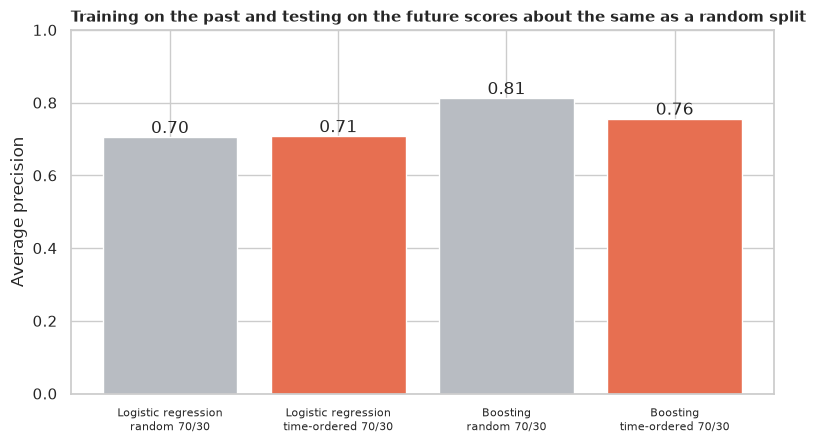

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.6))
labels = [f"{m.split(',')[0]}\n{e}" for m, e in validation.index]
colors = [GREY, ORANGE, GREY, ORANGE]
ax.bar(range(len(validation)), validation["AP"], color=colors)
for i, value in enumerate(validation["AP"]):
    ax.text(i, value + 0.012, f"{value:.2f}", ha="center")
ax.set_xticks(range(len(validation)), labels, fontsize=8)
ax.set_ylabel("Average precision")
ax.set_ylim(0, 1)
ax.set_title(
    "Training on the past and testing on the future scores about the same as a random split",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "06_time_ordered_validation.png", dpi=150)
plt.show()

**How to read this.** **Logistic regression is unchanged** (AP ≈ 0.705 on a random split vs ≈ 0.707 time-ordered). **Boosting drops from ≈ 0.81 to ≈ 0.76**, a modest decline of about 0.06 in AP, although its ROC-AUC is actually *higher* in the time-ordered test (0.984 vs 0.973). With only **107 frauds in the test set**, a 0.06 move in a single split is within what luck alone can do, so we **cannot reject H₀**, but we also can't rule out the first hint of drift: boosting may be fitting patterns specific to the first day. The scores are also a little below the 5-fold CV's (≈ 0.83) because each model here trains on 70% of the data, not 80%.

The caveat: **two days is too short to say anything about drift over months**. Fraud tactics evolve, and this check can't see that.

## 11. 🎯 Takeaways

1. **Accuracy is the wrong scoreboard for rare events.** Doing nothing is 99.83% accurate and catches 0 of 473 frauds. The legacy notebook's "99.9% accuracy" headline (and its mislabelled specificity and sensitivity) hid this.
2. **Duplicates are a quiet leak.** 1,081 duplicate rows (19 of them fraud) would sit on both sides of a split; remove them first.
3. **Fraud hides in the quiet hours.** The fraud rate peaks at about 1.45% in hour 2, roughly 9 times the overall 0.17% (χ² p ≈ 3e-101), because normal traffic collapses while fraud doesn't.
4. **The anonymised features separate fraud well**: `V14` alone has an AUC of about 0.95, and boosting or forests reach **AP ≈ 0.83**, far above logistic regression (≈ 0.74).
5. **"Sensible defaults" can silently break a model.** Automatic early stopping dropped boosting from AP ≈ 0.83 to ≈ 0.56 on this rare-event data, and balanced class weights simply traded precision for recall at the default threshold (recall ≈ 91%, precision ≈ 6%).
6. **Choose the threshold by cost.** With a 5-euro review, the best threshold (about 0.04) costs about 14.8k euros against about 15.9k at the default 0.5 and 58.6k for flagging nothing.
7. **A time-ordered test was mixed.** Logistic regression scored the same as on a random split, boosting lost about 0.06 AP (noisy: only 107 test frauds). Within two days we cannot tell drift from luck, and certainly not long-term drift.

## 12. ⚠️ Limitations and edge cases

- **Two days, one set of cardholders.** The data covers 48 hours in September 2013, so we can say nothing about seasonality, new fraud tactics or other countries. All fraud patterns learned here may already be out of date.
- **Anonymised features.** `V1` to `V28` are PCA outputs with no readable meaning, so we can rank them but cannot explain *why* `V14` signals fraud.
- **Few frauds.** 473 cases make every fraud-specific estimate (recall, precision, AP) noisy; the Nadeau-Bengio intervals reflect that.
- **The cost model is an assumption.** The 5-euro review cost and "a missed fraud costs its amount" are illustrative. Real costs include chargeback fees, customer annoyance and more.
- **Threshold chosen on the same out-of-fold data**, so its saving is slightly optimistic.
- **Labels may be incomplete.** "Normal" simply means not reported as fraud; some fraud may never have been detected.
- **Models are modestly tuned.** The tree ensembles use sensible settings without a full search, and gradient boosting with early stopping off is a deliberate choice for this rarity. A heavily tuned model might do a little better.
- **Not a production system.** There is no handling of concept drift, latency, explanation requirements or adversaries who adapt.

---
*Run `uv run jupyter nbconvert --to html --execute ML/credit-card-fraud-detection/credit_card_fraud_detection.ipynb --output-dir docs --output ml-credit-card-fraud-detection` to rebuild the web version (`docs/ml-credit-card-fraud-detection.html`).*